# AutoML Lab – Homework 1: ResNet-8 black-box objective

`train_and_validate(hyperparameters, seed, n_epochs) -> float` trains a self-implemented ResNet-8
on Fashion-MNIST (70/30 train/validation split) and returns the final-epoch **validation error**.

Stages: 0 setup · 1 data · 2 model · 3 helpers · 4 objective · 5 sanity checks · 6 search space · 7 grid / random search · 8 HPO runs · 9 results

## 0. Setup

In [1]:
# Run once if packages are missing (CUDA build of torch, matching your driver):
%pip install pandas numpy scikit-learn matplotlib
# %pip install torch torchvision --index-url https://download.pytorch.org/whl/cu130

Defaulting to user installation because normal site-packages is not writeable
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ---------------------- ----------------- 5.2/9.5 MB 28.7 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 29.6 MB/s  0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 42.6 MB/s  0:00:00
Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl (72 kB)

   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
 

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import train_test_split

In [3]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: running on CPU - the full HPO runs will be very slow.")

Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Data preparation
Done **once**, outside the objective. Everything ends up as tensors on `DEVICE`.

In [4]:
DATA_PATH  = r"D:\LUH\Semester-1 (WiSe 2026-27)\Lab - AutoML\Homework - 1 (ResNET-8 implementation)\dataset\fashion-mnist_train.csv"
SPLIT_SEED = 42          # fixed split for ALL evaluations (independent of the run seeds 42-46)

df_train = pd.read_csv(DATA_PATH)
df_train.head(2)

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
# 1.1 features / labels
df_train_X = df_train.drop(columns=["label"])
df_train_y = df_train["label"]

In [6]:
# 1.2a pixels -> float32 in [0, 1] (fixed constant, no leakage)
X = df_train_X.to_numpy(dtype=np.float32) / 255.0
y = df_train_y.to_numpy(dtype=np.int64)

In [7]:
# 1.2b stratified 70/30 split
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SPLIT_SEED
)

# 1.2c global standardization - statistics from the TRAINING split only
MEAN = X_train.mean()
STD  = X_train.std()
X_train = (X_train - MEAN) / STD
X_val   = (X_val   - MEAN) / STD

In [8]:
# Stage 1.2 checks
print("shapes:", X_train.shape, X_val.shape)                         # (42000, 784) (18000, 784)
print("train class counts:", np.bincount(y_train))                   # 4200 each
print(f"MEAN={MEAN:.4f}  STD={STD:.4f}")                             # ~0.286, ~0.353
print(f"train mean/std: {X_train.mean():.3f} / {X_train.std():.3f}")  # ~0 / ~1
print(f"val   mean/std: {X_val.mean():.3f} / {X_val.std():.3f}")      # close to 0 / 1

shapes: (42000, 784) (18000, 784)
train class counts: [4200 4200 4200 4200 4200 4200 4200 4200 4200 4200]
MEAN=0.2855  STD=0.3524
train mean/std: 0.000 / 1.000
val   mean/std: 0.006 / 1.004


In [9]:
# 1.3 flat rows (784) -> images (N, 1, 28, 28), then tensors on the device
X_train = X_train.reshape(-1, 1, 28, 28)
X_val   = X_val.reshape(-1, 1, 28, 28)

X_train_t = torch.from_numpy(X_train).to(DEVICE)   # float32
y_train_t = torch.from_numpy(y_train).to(DEVICE)   # int64
X_val_t   = torch.from_numpy(X_val).to(DEVICE)
y_val_t   = torch.from_numpy(y_val).to(DEVICE)

print(X_train_t.shape, X_val_t.shape)       # [42000, 1, 28, 28] [18000, 1, 28, 28]
print(X_train_t.dtype, y_train_t.dtype)     # torch.float32 torch.int64
print(X_train_t.device)

torch.Size([42000, 1, 28, 28]) torch.Size([18000, 1, 28, 28])
torch.float32 torch.int64
cuda:0


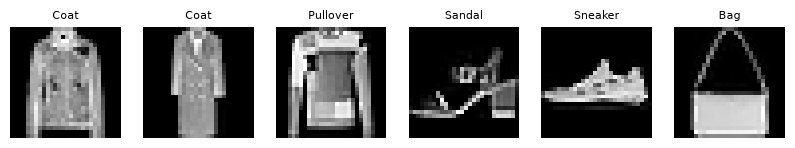

In [10]:
# Visual check: the image should match its label
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
try:
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 6, figsize=(10, 2))
    for ax, i in zip(axes, range(6)):
        ax.imshow(X_train[i, 0], cmap="gray")
        ax.set_title(CLASSES[y_train[i]], fontsize=8)
        ax.axis("off")
    plt.show()
except ImportError:
    print("matplotlib not installed - skipping visual check")

## 2. ResNet-8
CIFAR-style ResNet (He et al. 2016), depth 6n+2 with n=1. Projection (1×1 conv + BN) shortcuts
where the shape changes. Dropout after global average pooling.

In [11]:
class BasicBlock(nn.Module):
    """conv3x3 -> BN -> ReLU -> conv3x3 -> BN, + shortcut, -> ReLU"""

    def __init__(self, in_ch: int, out_ch: int, stride: int = 1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(out_ch)

        # shapes differ when downsampling or changing channels -> project the shortcut
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch),
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + self.shortcut(x)   # residual connection
        return F.relu(out)

In [12]:
class ResNet8(nn.Module):
    def __init__(self, num_classes: int = 10, dropout: float = 0.0):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
        )
        self.stage1  = BasicBlock(16, 16, stride=1)   # 16 x 28 x 28
        self.stage2  = BasicBlock(16, 32, stride=2)   # 32 x 14 x 14
        self.stage3  = BasicBlock(32, 64, stride=2)   # 64 x 7 x 7
        self.pool    = nn.AdaptiveAvgPool2d(1)        # 64 x 1 x 1
        self.dropout = nn.Dropout(p=dropout)          # after GAP, as recommended
        self.fc      = nn.Linear(64, num_classes)
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.pool(x).flatten(1)   # (N, 64)
        x = self.dropout(x)
        return self.fc(x)             # raw logits, no softmax

In [13]:
# Stage 2 checks
model = ResNet8(dropout=0.2).to(DEVICE)

print(model(X_train_t[:2]).shape)                         # torch.Size([2, 10])
print(sum(p.numel() for p in model.parameters()))         # 77754

model.eval()
with torch.no_grad():
    a, b = model(X_train_t[:4]), model(X_train_t[:4])
print("eval identical:", torch.equal(a, b))               # True

model.train()
with torch.no_grad():
    a, b = model(X_train_t[:4]), model(X_train_t[:4])
print("train identical:", torch.equal(a, b))              # False (dropout active)

torch.Size([2, 10])
77754
eval identical: True
train identical: False


## 3. Helpers
Config dict keys (the contract with every optimizer later):
`batch_size`, `lr`, `dropout`, `optimizer` (`"sgd"` / `"adam"`), and the active conditional HP
`momentum` (SGD) or `beta1` (Adam).

In [14]:
example_sgd  = {"batch_size": 128, "lr": 0.05,  "dropout": 0.2, "optimizer": "sgd",  "momentum": 0.9}
example_adam = {"batch_size": 128, "lr": 0.001, "dropout": 0.2, "optimizer": "adam", "beta1": 0.9}

In [15]:
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)          # no-op on CPU
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [16]:
def make_optimizer(config: dict, params):
    name, lr = config["optimizer"], config["lr"]
    if name == "sgd":
        return torch.optim.SGD(params, lr=lr, momentum=config["momentum"])
    if name == "adam":
        return torch.optim.Adam(params, lr=lr, betas=(config["beta1"], 0.999))
    raise ValueError(f"Unknown optimizer: {name}")

In [17]:
def iterate_minibatches(X, y, batch_size: int, generator: torch.Generator):
    n = X.shape[0]
    idx = torch.randperm(n, generator=generator).to(X.device)   # new order each call
    for start in range(0, n, batch_size):
        b = idx[start:start + batch_size]
        yield X[b], y[b]

In [18]:
@torch.no_grad()
def evaluate(model, X, y, batch_size: int = 1024):
    model.eval()                                   # dropout off, BN uses running stats
    total_loss, correct = 0.0, 0
    for start in range(0, X.shape[0], batch_size):
        xb, yb = X[start:start + batch_size], y[start:start + batch_size]
        logits = model(xb)
        total_loss += F.cross_entropy(logits, yb, reduction="sum").item()
        correct += (logits.argmax(dim=1) == yb).sum().item()
    n = X.shape[0]
    return total_loss / n, correct / n             # (val_loss, val_accuracy)

In [19]:
# Stage 3 checks
set_seed(42); a = torch.rand(3)
set_seed(42); b = torch.rand(3)
print("seed reproducible:", torch.equal(a, b))                       # True

m = ResNet8().to(DEVICE)
print(type(make_optimizer(example_sgd,  m.parameters())).__name__)   # SGD
print(type(make_optimizer(example_adam, m.parameters())).__name__)   # Adam

g = torch.Generator().manual_seed(42)
sizes = [xb.shape[0] for xb, _ in iterate_minibatches(X_train_t, y_train_t, 128, g)]
print(len(sizes), sum(sizes), sizes[-1])                             # 329 42000 16

g1 = torch.Generator().manual_seed(42); g2 = torch.Generator().manual_seed(42)
_, y1 = next(iterate_minibatches(X_train_t, y_train_t, 8, g1))
_, y2 = next(iterate_minibatches(X_train_t, y_train_t, 8, g2))
_, y3 = next(iterate_minibatches(X_train_t, y_train_t, 8, g1))
print(torch.equal(y1, y2), torch.equal(y1, y3))                      # True False

print(evaluate(m, X_val_t, y_val_t))                                 # (~2.3, ~0.1) untrained

seed reproducible: True
SGD
Adam
329 42000 16
True False
(2.3160468207465277, 0.14844444444444443)


## 4. Black-box objective
`run_training` does the work and returns a full record; `train_and_validate` is the black box
(config in, number out) and stores the record.

In [20]:
WORST_SCORE = 1.0   # validation error assigned to diverged/crashed runs


def run_training(config: dict, seed: int, n_epochs: int, data=None) -> dict:
    X_tr, y_tr, X_v, y_v = data if data is not None else (X_train_t, y_train_t, X_val_t, y_val_t)
    t0 = time.perf_counter()

    # 1) seed everything; separate generator for data shuffling
    set_seed(seed)
    gen = torch.Generator().manual_seed(seed)

    # 2) fresh model + optimizer from the config
    model = ResNet8(dropout=config["dropout"]).to(DEVICE)
    optimizer = make_optimizer(config, model.parameters())

    curve, status = [], "ok"

    # 3) train / validate loop
    for epoch in range(1, n_epochs + 1):
        model.train()                                   # re-set every epoch (evaluate() switches to eval)
        loss_sum = torch.zeros((), device=DEVICE)
        n_seen = 0

        for xb, yb in iterate_minibatches(X_tr, y_tr, config["batch_size"], gen):
            logits = model(xb)
            loss = F.cross_entropy(logits, yb)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            loss_sum += loss.detach() * xb.shape[0]     # stays on device, no sync per step
            n_seen += xb.shape[0]

        train_loss = (loss_sum / n_seen).item()         # one sync per epoch
        if not np.isfinite(train_loss):                 # NaN/inf -> learning rate blew up
            status = "diverged"
            break

        val_loss, val_acc = evaluate(model, X_v, y_v)
        curve.append({"epoch": epoch, "train_loss": train_loss,
                      "val_loss": val_loss, "val_acc": val_acc})

    # 4) score = final-epoch validation error (minimization, like SMAC3)
    if status == "ok":
        val_acc = curve[-1]["val_acc"]
        val_error = 1.0 - val_acc
    else:
        val_acc, val_error = None, WORST_SCORE

    return {
        "config": dict(config),
        "seed": seed,
        "n_epochs": n_epochs,
        "status": status,
        "val_error": val_error,
        "val_acc": val_acc,
        "curve": curve,                                  # per-epoch learning curve
        "train_time_s": time.perf_counter() - t0,        # cost, for multi-objective later
    }

In [21]:
EVAL_RECORDS = []   # temporary in-memory log; becomes a file logger in the HPO stage


def train_and_validate(hyperparameters: dict, seed: int, n_epochs: int) -> float:
    t0 = time.perf_counter()
    try:
        record = run_training(hyperparameters, seed, n_epochs)
    except Exception as e:                               # e.g. out-of-memory -> don't kill the whole HPO run
        record = {"config": dict(hyperparameters), "seed": seed, "n_epochs": n_epochs,
                  "status": f"crashed: {type(e).__name__}: {e}",
                  "val_error": WORST_SCORE, "val_acc": None, "curve": [],
                  "train_time_s": time.perf_counter() - t0}   # same keys as a normal record
        print("WARNING:", record["status"])
    EVAL_RECORDS.append(record)
    return record["val_error"]

In [22]:
# Stage 4 smoke test (1 epoch)
score = train_and_validate(example_adam, seed=42, n_epochs=1)
rec = EVAL_RECORDS[-1]
print("val_error:", round(score, 4))                               # ~0.15 or lower
print("status:", rec["status"], "| time (s):", round(rec["train_time_s"], 1))
print(rec["curve"])

val_error: 0.1847
status: ok | time (s): 2.9
[{'epoch': 1, 'train_loss': 0.8215017318725586, 'val_loss': 0.5078978763156468, 'val_acc': 0.8153333333333334}]


## 5. Sanity checks
All five must pass before any HPO run.

In [23]:
# 5a Overfit a tiny subset (does learning work at all?)
tiny = (X_train_t[:256], y_train_t[:256], X_train_t[:256], y_train_t[:256])   # train = val on purpose
cfg  = {"batch_size": 32, "lr": 1e-3, "dropout": 0.0, "optimizer": "adam", "beta1": 0.9}

rec = run_training(cfg, seed=42, n_epochs=50, data=tiny)
print("tiny-set accuracy:", rec["curve"][-1]["val_acc"])     # expect ~1.0

tiny-set accuracy: 1.0


In [24]:
# 5b One full known-good run (is performance realistic?)
good = {"batch_size": 128, "lr": 1e-3, "dropout": 0.0, "optimizer": "adam", "beta1": 0.9}
rec = run_training(good, seed=42, n_epochs=10)

print("epoch | train_loss | val_loss | val_acc")
for c in rec["curve"]:
    print(f"{c['epoch']:>5} | {c['train_loss']:.3f}      | {c['val_loss']:.3f}    | {c['val_acc']:.4f}")
print("val_error:", round(rec["val_error"], 4), "| time (s):", round(rec["train_time_s"], 1))   # val_acc >~ 0.90

epoch | train_loss | val_loss | val_acc
    1 | 0.771      | 0.535    | 0.8083
    2 | 0.408      | 0.450    | 0.8368
    3 | 0.336      | 0.370    | 0.8701
    4 | 0.304      | 0.325    | 0.8821
    5 | 0.274      | 0.292    | 0.8931
    6 | 0.256      | 0.341    | 0.8798
    7 | 0.239      | 0.291    | 0.8975
    8 | 0.222      | 0.365    | 0.8644
    9 | 0.207      | 0.325    | 0.8806
   10 | 0.192      | 0.271    | 0.9004
val_error: 0.0996 | time (s): 23.1


In [25]:
# 5c Timing (does the homework fit the hardware?)
_ = run_training(good, seed=0, n_epochs=1)          # warm-up (first GPU call is slow)

times = {}
for bs in [32, 64, 128, 256]:
    t = run_training(dict(good, batch_size=bs), seed=0, n_epochs=1)["train_time_s"]
    times[bs] = t * 10                                # ~ one full 10-epoch evaluation
    print(f"batch {bs:>3}: ~{times[bs]:.0f} s per evaluation")

avg = np.mean(list(times.values()))
print(f"Estimated total for 1,000 evaluations: ~{avg * 1000 / 3600:.1f} hours")

batch  32: ~87 s per evaluation
batch  64: ~44 s per evaluation
batch 128: ~22 s per evaluation
batch 256: ~16 s per evaluation
Estimated total for 1,000 evaluations: ~11.7 hours


In [26]:
# 5d Reproducibility (does the seed control everything?)
a = run_training(good, seed=42, n_epochs=2)["val_error"]
b = run_training(good, seed=42, n_epochs=2)["val_error"]
c = run_training(good, seed=43, n_epochs=2)["val_error"]
print("same seed :", a, b)     # identical (or near-identical on GPU)
print("other seed:", c)        # slightly different

same seed : 0.16316666666666668 0.16316666666666668
other seed: 0.13022222222222224


In [27]:
# 5e Failure handling (bad configs are recorded, not fatal)
s1 = train_and_validate({"batch_size": 128, "lr": 1e-3, "dropout": 0.0, "optimizer": "adamw"}, 42, 1)
print(s1, "|", EVAL_RECORDS[-1]["status"])     # 1.0 | crashed: ValueError: Unknown optimizer: adamw

s2 = train_and_validate({"batch_size": 128, "lr": 1e4, "dropout": 0.0, "optimizer": "sgd", "momentum": 0.9}, 42, 1)
print(s2, "|", EVAL_RECORDS[-1]["status"])     # usually 1.0 | diverged (ok with a bad score is fine too)

1.0 | crashed: ValueError: Unknown optimizer: adamw
1.0 | diverged


In [28]:
# 5f Clean up - sanity-check runs must not end up in the HPO results
EVAL_RECORDS.clear()
print("records:", len(EVAL_RECORDS))

records: 0


### Pass checklist
| Check | Pass if |
|---|---|
| 5a Overfit | tiny-set accuracy ≈ 1.0 |
| 5b Known-good | val accuracy ≳ 0.90 after 10 epochs, loss decreasing |
| 5c Timing | estimated total fits the schedule |
| 5d Reproducible | same seed → same score, other seed → different score |
| 5e Failures | crash / divergence → 1.0 with a clear status, nothing stops |

Next: search space, grid size (≤ 100), grid search, random search, file logger.

## 6. Search space
Same bounds for both methods, so we compare search *strategies*, not search spaces.

| HP | Type | Range (random search) | Grid values |
|---|---|---|---|
| `batch_size` | categorical | {32, 64, 128, 256} | {64, 256} |
| `lr` | float, log scale | [1e-4, 1e-1] | 5 log-spaced values |
| `dropout` | float | [0.0, 0.5] | {0.0, 0.3} |
| `optimizer` | categorical | {sgd, adam} | {sgd, adam} |
| ↳ `momentum` (if sgd) | float | [0.0, 0.99] | {0.0, 0.5, 0.9} |
| ↳ `beta1` (if adam) | float | [0.8, 0.99] | {0.8, 0.95} |

Conditional HPs only exist when their parent is active, so the grid size is
**2 × 5 × 2 × (3 + 2) = 100**, not the naive full product 2 × 5 × 2 × 2 × 3 × 2 = 240.

In [29]:
import json
import os
from datetime import datetime
from pathlib import Path

# order matters: a conditional HP must come after its parent
SEARCH_SPACE = {
    "batch_size": {"type": "categorical", "choices": [32, 64, 128, 256]},
    "lr":         {"type": "float", "low": 1e-4, "high": 1e-1, "log": True},
    "dropout":    {"type": "float", "low": 0.0,  "high": 0.5},
    "optimizer":  {"type": "categorical", "choices": ["sgd", "adam"]},
    "momentum":   {"type": "float", "low": 0.0,  "high": 0.99, "condition": ("optimizer", "sgd")},
    "beta1":      {"type": "float", "low": 0.8,  "high": 0.99, "condition": ("optimizer", "adam")},
}

GRID_VALUES = {
    "batch_size": [64, 256],
    "lr":         [float(f"{v:.6g}") for v in np.logspace(-4, -1, 5)],   # 1e-4 ... 1e-1
    "dropout":    [0.0, 0.3],
    "optimizer":  ["sgd", "adam"],
    "momentum":   [0.0, 0.5, 0.9],
    "beta1":      [0.8, 0.95],
}

def is_active(name: str, config: dict) -> bool:
    cond = SEARCH_SPACE[name].get("condition")
    return cond is None or config.get(cond[0]) == cond[1]

# sanity: every grid value lies inside the search space
for name, values in GRID_VALUES.items():
    spec = SEARCH_SPACE[name]
    for v in values:
        ok = v in spec["choices"] if spec["type"] == "categorical" else spec["low"] <= v <= spec["high"]
        assert ok, f"grid value {v} for {name} is outside the search space"
print("lr grid:", GRID_VALUES["lr"])

lr grid: [0.0001, 0.000562341, 0.00316228, 0.0177828, 0.1]


In [30]:
def build_grid(space: dict, grid_values: dict) -> list:
    """Cartesian product over unconditional HPs, conditional HPs expanded only where active."""
    configs = [{}]
    for name, spec in space.items():
        expanded = []
        for c in configs:
            if "condition" in spec and c.get(spec["condition"][0]) != spec["condition"][1]:
                expanded.append(c)                       # inactive -> HP absent, no duplicates
            else:
                expanded += [dict(c, **{name: v}) for v in grid_values[name]]
        configs = expanded
    return configs

# Work out the grid size BEFORE running anything
GRID = build_grid(SEARCH_SPACE, GRID_VALUES)
n_sgd  = sum(c["optimizer"] == "sgd" for c in GRID)
n_adam = sum(c["optimizer"] == "adam" for c in GRID)
print(f"grid size = {len(GRID)}  (sgd: {n_sgd}, adam: {n_adam})")   # 100 (60, 40)
assert len(GRID) == 100, "grid must fit the budget of 100 evaluations"
assert len({json.dumps(c, sort_keys=True) for c in GRID}) == len(GRID), "duplicate configs in grid"
GRID[:2]

grid size = 100  (sgd: 60, adam: 40)


[{'batch_size': 64,
  'lr': 0.0001,
  'dropout': 0.0,
  'optimizer': 'sgd',
  'momentum': 0.0},
 {'batch_size': 64,
  'lr': 0.0001,
  'dropout': 0.0,
  'optimizer': 'sgd',
  'momentum': 0.5}]

In [31]:
# Expected compute (uses the per-batch-size timings from 5c; lr/dropout don't change cost)
SEEDS, BUDGET, N_EPOCHS = [42, 43, 44, 45, 46], 100, 10

if "times" in globals():
    grid_s   = np.mean([times[bs] for bs in GRID_VALUES["batch_size"]])
    random_s = np.mean([times[bs] for bs in SEARCH_SPACE["batch_size"]["choices"]])
    n_runs   = len(SEEDS) * BUDGET
    print(f"grid  : ~{grid_s:.0f} s/eval -> ~{grid_s * n_runs / 3600:.1f} h")
    print(f"random: ~{random_s:.0f} s/eval -> ~{random_s * n_runs / 3600:.1f} h")
    print(f"total : ~{(grid_s + random_s) * n_runs / 3600:.1f} h")

grid  : ~30 s/eval -> ~4.1 h
random: ~42 s/eval -> ~5.9 h
total : ~10.0 h


## 7. Grid search, random search, logger
Both optimizers use an **ask/tell** interface (`ask()` → config, `tell(config, score)`),
so Bayesian optimization can be swapped in later without touching the run loop.

In [32]:
class GridSearch:
    """Evaluates every grid config once. Order is shuffled with the seed: a grid has no
    natural order, and a fixed order would bias the best-so-far curve."""

    def __init__(self, space: dict, grid_values: dict, seed: int):
        self.configs = build_grid(space, grid_values)
        np.random.default_rng(seed).shuffle(self.configs)
        self.i = 0

    def ask(self):
        if self.i >= len(self.configs):
            return None                                  # grid exhausted
        config = dict(self.configs[self.i])
        self.i += 1
        return config

    def tell(self, config: dict, score: float) -> None:
        pass                                             # grid search ignores feedback


class RandomSearch:
    """Samples uniformly from the search space (log-uniform for log-scale HPs)."""

    def __init__(self, space: dict, seed: int):
        self.space = space
        self.rng = np.random.default_rng(seed)           # own RNG, independent of training RNG

    def _sample(self, spec: dict):
        if spec["type"] == "categorical":
            return spec["choices"][self.rng.integers(len(spec["choices"]))]
        if spec.get("log"):
            return float(np.exp(self.rng.uniform(np.log(spec["low"]), np.log(spec["high"]))))
        return float(self.rng.uniform(spec["low"], spec["high"]))

    def ask(self) -> dict:
        config = {}
        for name, spec in self.space.items():            # parents before children
            cond = spec.get("condition")
            if cond is None or config.get(cond[0]) == cond[1]:
                config[name] = self._sample(spec)
        return config

    def tell(self, config: dict, score: float) -> None:
        pass                                             # random search ignores feedback


def make_hpo_optimizer(method: str, seed: int):
    if method == "grid":
        return GridSearch(SEARCH_SPACE, GRID_VALUES, seed)
    if method == "random":
        return RandomSearch(SEARCH_SPACE, seed)
    raise ValueError(f"Unknown HPO method: {method}")

In [33]:
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
LOG_PATH = RESULTS_DIR / "hpo_results.jsonl"      # one JSON line per evaluation


def load_records(log_path: Path) -> list:
    """Read all evaluation records; skips a half-written last line after a crash."""
    if not Path(log_path).exists():
        return []
    records = []
    with open(log_path) as f:
        for line in f:
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError:
                pass
    return records


def append_record(log_path: Path, record: dict) -> None:
    with open(log_path, "a") as f:
        f.write(json.dumps(record, default=lambda o: o.item() if hasattr(o, "item") else str(o)) + "\n")
        f.flush()
        os.fsync(f.fileno())                             # on disk before the next evaluation starts


def run_hpo(method: str, seed: int, budget: int = 100, n_epochs: int = 10,
            log_path: Path = LOG_PATH, verbose: bool = True) -> list:
    """One HPO run. Resumable: evaluations already in the log are replayed, not re-trained."""
    opt = make_hpo_optimizer(method, seed)
    done = sorted((r for r in load_records(log_path) if r["method"] == method and r["seed"] == seed),
                  key=lambda r: r["eval_index"])
    best = min((r["val_error"] for r in done), default=float("inf"))
    if done and verbose:
        print(f"[{method} | seed {seed}] resuming after {len(done)} logged evaluations")

    for i in range(1, budget + 1):
        config = opt.ask()
        if config is None:
            break

        if i <= len(done):                               # replay: keeps the optimizer's state exact
            if done[i - 1]["config"] != config:
                raise RuntimeError(f"Log does not match replay at eval {i} ({method}, seed {seed}). "
                                   "Search space changed? Use a new LOG_PATH.")
            opt.tell(config, done[i - 1]["val_error"])
            continue

        score = train_and_validate(config, seed, n_epochs)
        rec = EVAL_RECORDS[-1]
        opt.tell(config, score)
        best = min(best, score)

        append_record(log_path, {
            "method": method, "seed": seed, "eval_index": i, "config": config,
            "val_error": score, "val_acc": rec["val_acc"], "status": rec["status"],
            "train_time_s": rec["train_time_s"], "n_epochs": n_epochs,
            "curve": rec["curve"], "device": str(DEVICE),
            "timestamp": datetime.now().isoformat(timespec="seconds"),
        })
        if verbose:
            print(f"[{method:>6} | seed {seed}] {i:>3}/{budget}  err={score:.4f}  best={best:.4f}  "
                  f"{rec['train_time_s']:5.1f}s  {rec['status']}")

    return [r for r in load_records(log_path) if r["method"] == method and r["seed"] == seed]

In [34]:
# Dry run: tiny budget, 1 epoch, separate log file. Checks logging AND resuming, then cleans up.
DRY_LOG = RESULTS_DIR / "dry_run.jsonl"
DRY_LOG.unlink(missing_ok=True)

for method in ["random", "grid"]:
    run_hpo(method, seed=42, budget=3, n_epochs=1, log_path=DRY_LOG)

n_lines = len(load_records(DRY_LOG))
for method in ["random", "grid"]:                        # second call must skip everything
    run_hpo(method, seed=42, budget=3, n_epochs=1, log_path=DRY_LOG, verbose=False)

print("records after first pass :", n_lines)                           # 6
print("records after second pass:", len(load_records(DRY_LOG)))        # 6 -> resume works
print(json.dumps(load_records(DRY_LOG)[0], indent=1)[:600])
DRY_LOG.unlink()
EVAL_RECORDS.clear()

[random | seed 42]   1/3  err=0.1519  best=0.1519    8.4s  ok
[random | seed 42]   2/3  err=0.1580  best=0.1519    8.2s  ok
[random | seed 42]   3/3  err=0.3167  best=0.1519    2.0s  ok
[  grid | seed 42]   1/3  err=0.4170  best=0.4170    1.5s  ok
[  grid | seed 42]   2/3  err=0.3811  best=0.3811    4.6s  ok
[  grid | seed 42]   3/3  err=0.8940  best=0.3811    1.5s  ok
records after first pass : 6
records after second pass: 6
{
 "method": "random",
 "seed": 42,
 "eval_index": 1,
 "config": {
  "batch_size": 32,
  "lr": 0.002073171926369454,
  "dropout": 0.42929895995569123,
  "optimizer": "adam",
  "beta1": 0.9324999255212791
 },
 "val_error": 0.15194444444444444,
 "val_acc": 0.8480555555555556,
 "status": "ok",
 "train_time_s": 8.392926799999259,
 "n_epochs": 1,
 "curve": [
  {
   "epoch": 1,
   "train_loss": 0.6893825531005859,
   "val_loss": 0.4076897650824653,
   "val_acc": 0.8480555555555556
  }
 ],
 "device": "cuda",
 "timestamp": "2026-10-24T20:42:35"
}


## 8. HPO runs (≈10 h on the RTX 4060)
2 methods × 5 seeds × 100 evaluations × 10 epochs. Seeds are the outer loop, so if time runs
out you still have complete seeds for **both** methods.

Every evaluation is written to `results/hpo_results.jsonl` immediately. If the kernel dies or
the laptop restarts: run sections 0–4 and 6–7 again, then this cell. It resumes where it stopped.
Keep the laptop plugged in and sleep disabled.

In [35]:
t_start = time.perf_counter()
for seed in SEEDS:
    for method in ["random", "grid"]:
        run_hpo(method, seed, budget=BUDGET, n_epochs=N_EPOCHS)
        EVAL_RECORDS.clear()                             # results live in the log file
print(f"Done in {(time.perf_counter() - t_start) / 3600:.1f} h")

[random | seed 42]   1/100  err=0.0878  best=0.0878   89.1s  ok
[random | seed 42]   2/100  err=0.0863  best=0.0863   79.5s  ok
[random | seed 42]   3/100  err=0.1788  best=0.0863   20.5s  ok
[random | seed 42]   4/100  err=0.0964  best=0.0863   15.4s  ok
[random | seed 42]   5/100  err=0.1134  best=0.0863   85.7s  ok
[random | seed 42]   6/100  err=0.0852  best=0.0852   87.2s  ok
[random | seed 42]   7/100  err=0.1160  best=0.0852   22.5s  ok
[random | seed 42]   8/100  err=0.1103  best=0.0852   20.8s  ok
[random | seed 42]   9/100  err=0.2939  best=0.0852   40.5s  ok
[random | seed 42]  10/100  err=0.1790  best=0.0852   42.5s  ok
[random | seed 42]  11/100  err=0.3400  best=0.0852   15.5s  ok
[random | seed 42]  12/100  err=0.0869  best=0.0852   15.8s  ok
[random | seed 42]  13/100  err=0.1054  best=0.0852   96.1s  ok
[random | seed 42]  14/100  err=0.0846  best=0.0846   15.4s  ok
[random | seed 42]  15/100  err=0.2505  best=0.0846   23.3s  ok
[random | seed 42]  16/100  err=0.0901  

## 9. Results
Needs matplotlib (`%pip install matplotlib`). Can be run any time, also while section 8
is still running in another kernel, since it only reads the log file.

In [36]:
records = load_records(LOG_PATH)
df = pd.json_normalize(records)                          # config.* columns; inactive HPs are NaN
df = df.sort_values(["method", "seed", "eval_index"]).reset_index(drop=True)
df["best_so_far"] = df.groupby(["method", "seed"])["val_error"].cummin()

print("evaluations per method/seed:")
print(df.groupby(["method", "seed"]).size().unstack(0), "\n")
print("status counts:")
print(df.groupby("method")["status"].value_counts().unstack(fill_value=0), "\n")
print("compute (h):", (df.groupby("method")["train_time_s"].sum() / 3600).round(2).to_dict())

evaluations per method/seed:
method  grid  random
seed                
42       100     100
43       100     100
44       100     100
45       100     100
46       100     100 

status counts:
status   ok
method     
grid    500
random  500 

compute (h): {'grid': 3.94, 'random': 5.93}


In [37]:
# Final incumbent per method and seed (lowest validation error found within the budget)
final = df.groupby(["method", "seed"])["val_error"].min().unstack(0)
print(final.round(4), "\n")
print("mean ± std over seeds:")
for m in final.columns:
    print(f"  {m:>6}: {final[m].mean():.4f} ± {final[m].std():.4f}")

cfg_cols = [c for c in df.columns if c.startswith("config.")]
best_rows = df.loc[df.groupby("method")["val_error"].idxmin(), ["method", "seed", "val_error"] + cfg_cols]
best_rows

method    grid  random
seed                  
42      0.0827  0.0748
43      0.0752  0.0780
44      0.0794  0.0777
45      0.0843  0.0784
46      0.0801  0.0747 

mean ± std over seeds:
    grid: 0.0803 ± 0.0035
  random: 0.0767 ± 0.0018


,method,seed,val_error,config.batch_size,config.lr,config.dropout,config.optimizer,config.beta1,config.momentum
150,grid,43,0.075222,64,0.017783,0.000000,adam,0.950000,NaN
997,random,46,0.074722,32,0.006841,0.113253,adam,0.849561,NaN


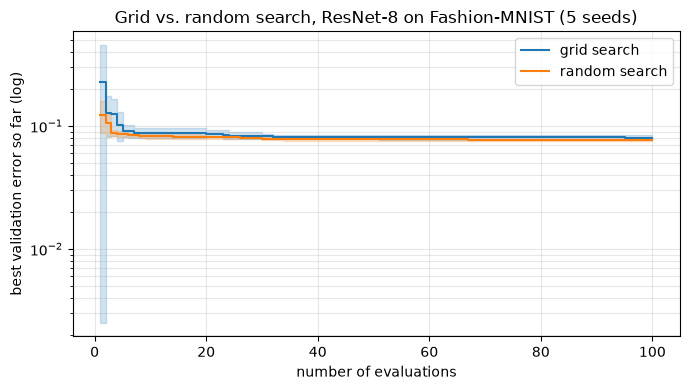

In [38]:
import matplotlib.pyplot as plt

# Best-so-far validation error vs. number of evaluations (mean ± std over seeds)
fig, ax = plt.subplots(figsize=(7, 4))
for method, color in [("grid", "tab:blue"), ("random", "tab:orange")]:
    g = df[df["method"] == method].groupby("eval_index")["best_so_far"].agg(["mean", "std"])
    lo = np.clip(g["mean"] - g["std"], 1e-3, None)       # keep the band positive on a log axis
    ax.step(g.index, g["mean"], where="post", color=color, label=f"{method} search")
    ax.fill_between(g.index, lo, g["mean"] + g["std"], step="post", color=color, alpha=0.2)
ax.set_yscale("log")
ax.set_xlabel("number of evaluations")
ax.set_ylabel("best validation error so far (log)")
ax.set_title(f"Grid vs. random search, ResNet-8 on Fashion-MNIST ({df['seed'].nunique()} seeds)")
ax.legend()
ax.grid(alpha=0.3, which="both")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "best_so_far.png", dpi=200)
plt.show()

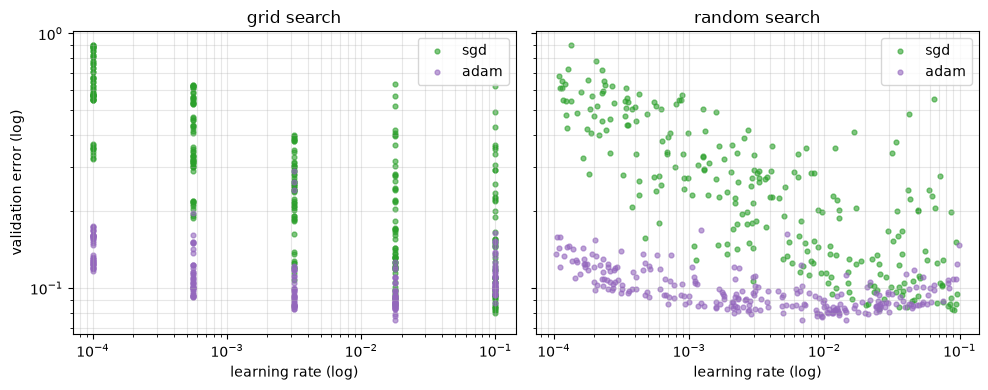

In [39]:
# Why: validation error vs. learning rate, per optimizer (all evaluations)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, method in zip(axes, ["grid", "random"]):
    sub = df[(df["method"] == method) & (df["status"] == "ok")]
    for opt_name, color in [("sgd", "tab:green"), ("adam", "tab:purple")]:
        s = sub[sub["config.optimizer"] == opt_name]
        ax.scatter(s["config.lr"], s["val_error"], s=12, alpha=0.6, color=color, label=opt_name)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("learning rate (log)"); ax.set_title(f"{method} search")
    ax.grid(alpha=0.3, which="both"); ax.legend()
axes[0].set_ylabel("validation error (log)")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "error_vs_lr.png", dpi=200)
plt.show()

**Design decisions to defend in Q&A**
- Objective returns final-epoch validation **error** (minimization, as SMAC3); diverged/crashed runs get 1.0.
- Same search-space bounds for both methods; LR is log-scale (log-uniform sampling, log-spaced grid).
- Conditional HPs only exist when active → grid of exactly 100 without duplicates.
- Grid order shuffled per seed; random search has its own seeded RNG, separate from the training RNG.
- Within one seed, every config starts from the same initial weights (common random numbers).
- Every evaluation logs config, score, status, learning curve and wall-clock time → reusable for
  surrogate models (Seminar 2), BO baselines (Seminar 4) and multi-objective/cost analyses (Seminar 6).